In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import drive

drive.mount('/content/drive')

print("Google Drive mounted successfully.")

Mounted at /content/drive
Google Drive mounted successfully.


In [ ]:
PROJECT_PATH = "/content/drive/MyDrive/AML_Project"

OUTPUT_PATH = os.path.join(
    PROJECT_PATH,
    "outputs"
)

FORENSIC_PATH = os.path.join(
    OUTPUT_PATH,
    "forensic"
)

FA04_PATH = os.path.join(
    FORENSIC_PATH,
    "FA04"
)

os.makedirs(FA04_PATH, exist_ok=True)

print("FA04 output folder:")
print(FA04_PATH)

FA04 output folder:
/content/drive/MyDrive/AML_Project/outputs/forensic/FA04


In [ ]:
TRANSACTION_FILE = os.path.join(
    OUTPUT_PATH,
    "integrated_transaction_risk_results.csv"
)

df = pd.read_csv(TRANSACTION_FILE)

print("Dataset loaded successfully.")
print("Shape:", df.shape)

Dataset loaded successfully.
Shape: (149994, 35)


In [ ]:
df["timestamp"] = pd.to_datetime(
    df["timestamp"],
    errors="coerce"
)

print("Timestamp conversion completed.")

print(
    "Invalid timestamps:",
    df["timestamp"].isna().sum()
)

Timestamp conversion completed.
Invalid timestamps: 0


In [ ]:
df["date"] = df["timestamp"].dt.date

df["year"] = df["timestamp"].dt.year

df["month"] = df["timestamp"].dt.month

df["day"] = df["timestamp"].dt.day

df["hour"] = df["timestamp"].dt.hour

df["day_of_week"] = df["timestamp"].dt.day_name()

df["day_of_week_num"] = df["timestamp"].dt.dayofweek

print("Temporal features created.")

Temporal features created.


In [ ]:
daily_activity = (
    df.groupby("date")
      .agg(
          transaction_count=("transaction_id", "count"),
          total_amount=("amount", "sum"),
          average_amount=("amount", "mean"),
          fraud_count=("is_fraud", "sum")
      )
      .reset_index()
)

daily_activity["fraud_rate_percent"] = (
    daily_activity["fraud_count"]
    /
    daily_activity["transaction_count"]
    * 100
)

display(daily_activity.head(10))

,date,transaction_count,total_amount,average_amount,fraud_count,fraud_rate_percent
0,2026-01-01,21203,5.010910e+08,23633.025562,0,0.000000
1,2026-01-02,21312,4.947803e+08,23216.042605,0,0.000000
2,2026-01-03,21657,5.211974e+08,24066.002641,178,0.821905
3,2026-01-04,21081,4.912507e+08,23303.008181,243,1.152697
4,2026-01-05,21862,5.310456e+08,24290.804076,396,1.811362
5,2026-01-06,21807,5.744521e+08,26342.554381,631,2.893566
6,2026-01-07,21072,5.015063e+08,23799.651650,2,0.009491


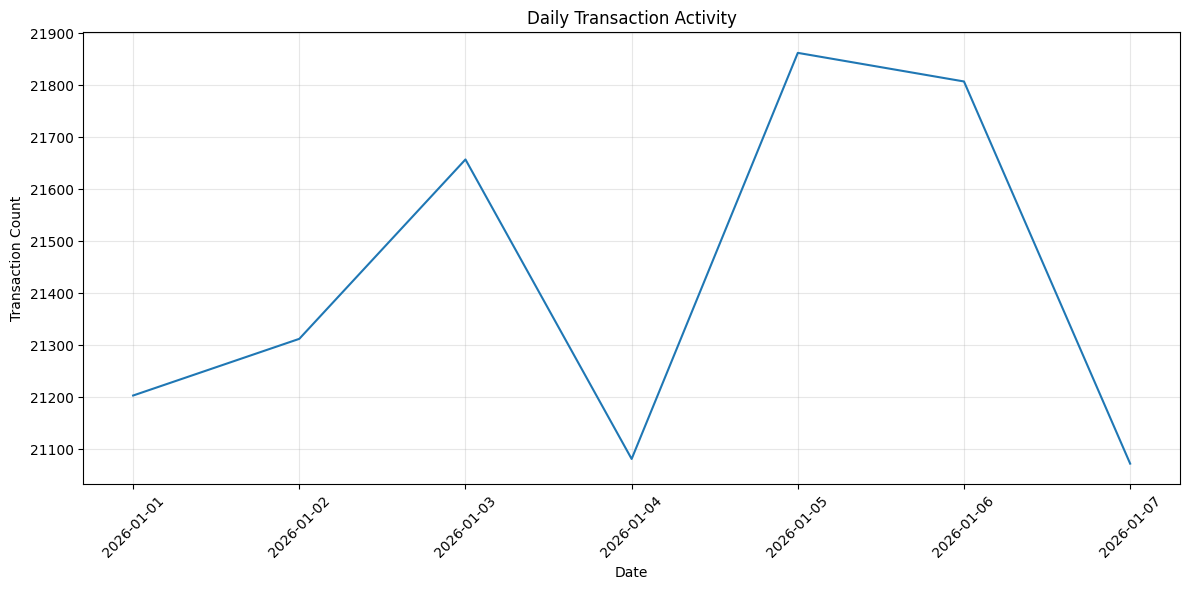

In [ ]:
plt.figure(figsize=(12, 6))

plt.plot(
    daily_activity["date"],
    daily_activity["transaction_count"]
)

plt.xlabel("Date")
plt.ylabel("Transaction Count")
plt.title("Daily Transaction Activity")

plt.xticks(rotation=45)

plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(
        FA04_PATH,
        "daily_transaction_activity.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

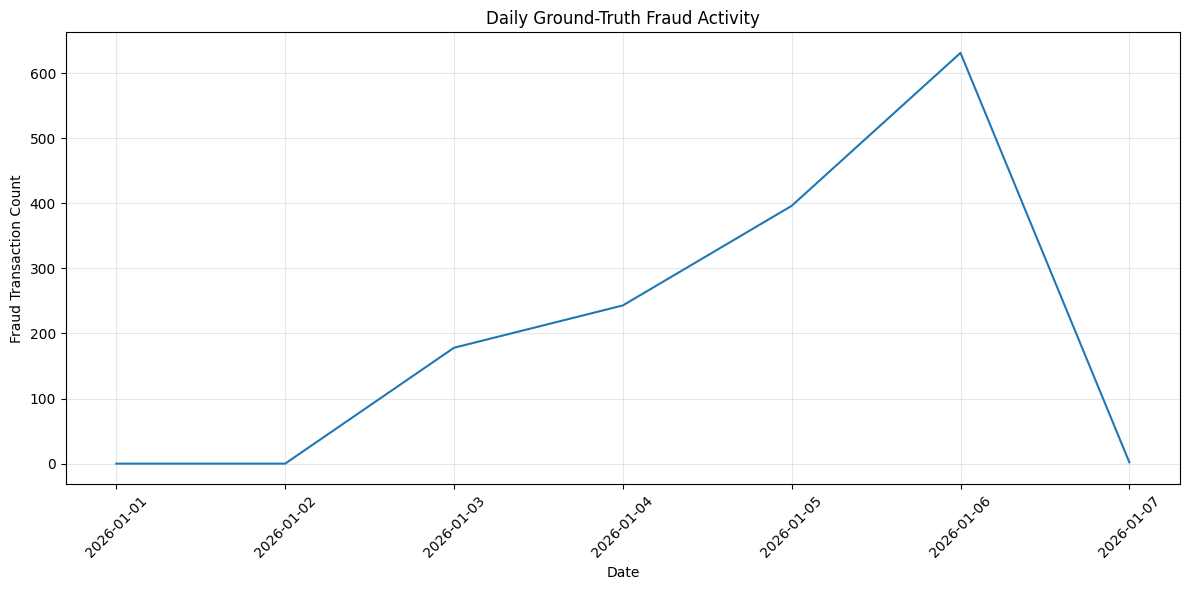

In [ ]:
plt.figure(figsize=(12, 6))

plt.plot(
    daily_activity["date"],
    daily_activity["fraud_count"]
)

plt.xlabel("Date")
plt.ylabel("Fraud Transaction Count")
plt.title("Daily Ground-Truth Fraud Activity")

plt.xticks(rotation=45)

plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(
        FA04_PATH,
        "daily_fraud_activity.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
daily_mean = daily_activity["transaction_count"].mean()

daily_std = daily_activity["transaction_count"].std()

spike_threshold = daily_mean + (2 * daily_std)

daily_activity["transaction_spike_flag"] = (
    daily_activity["transaction_count"]
    >
    spike_threshold
).astype(int)

temporal_spikes = daily_activity[
    daily_activity["transaction_spike_flag"] == 1
].copy()

print(f"Mean daily transactions: {daily_mean:.2f}")
print(f"Standard deviation: {daily_std:.2f}")
print(f"Spike threshold: {spike_threshold:.2f}")
print(
    "Number of spike days:",
    len(temporal_spikes)
)

Mean daily transactions: 21427.71
Standard deviation: 340.51
Spike threshold: 22108.73
Number of spike days: 0


In [ ]:
display(
    temporal_spikes[
        [
            "date",
            "transaction_count",
            "total_amount",
            "average_amount",
            "fraud_count",
            "fraud_rate_percent"
        ]
    ]
)

,date,transaction_count,total_amount,average_amount,fraud_count,fraud_rate_percent


In [ ]:
hourly_activity = (
    df.groupby("hour")
      .agg(
          transaction_count=("transaction_id", "count"),
          total_amount=("amount", "sum"),
          fraud_count=("is_fraud", "sum")
      )
      .reset_index()
)

hourly_activity["fraud_rate_percent"] = (
    hourly_activity["fraud_count"]
    /
    hourly_activity["transaction_count"]
    * 100
)

display(hourly_activity)

,hour,transaction_count,total_amount,fraud_count,fraud_rate_percent
0,0,69,5.919876e+06,69,100.000000
1,1,43,2.783837e+06,43,100.000000
2,2,84,6.081544e+06,84,100.000000
3,3,51,4.570551e+06,51,100.000000
4,4,58,3.727524e+06,58,100.000000
5,5,71,5.474410e+06,71,100.000000
6,6,77,5.656287e+06,77,100.000000
7,7,9495,2.232920e+08,67,0.705635
8,8,9253,2.281106e+08,77,0.832163
9,9,9482,2.336319e+08,44,0.464037


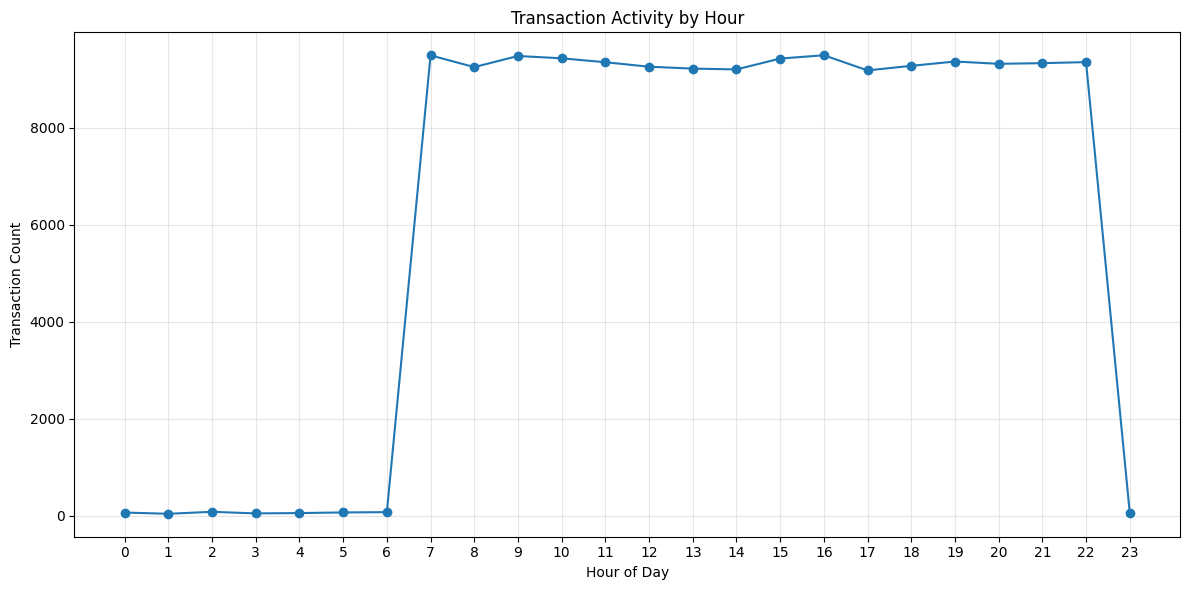

In [ ]:
plt.figure(figsize=(12, 6))

plt.plot(
    hourly_activity["hour"],
    hourly_activity["transaction_count"],
    marker="o"
)

plt.xlabel("Hour of Day")
plt.ylabel("Transaction Count")
plt.title("Transaction Activity by Hour")

plt.xticks(range(24))

plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(
        FA04_PATH,
        "hourly_transaction_activity.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

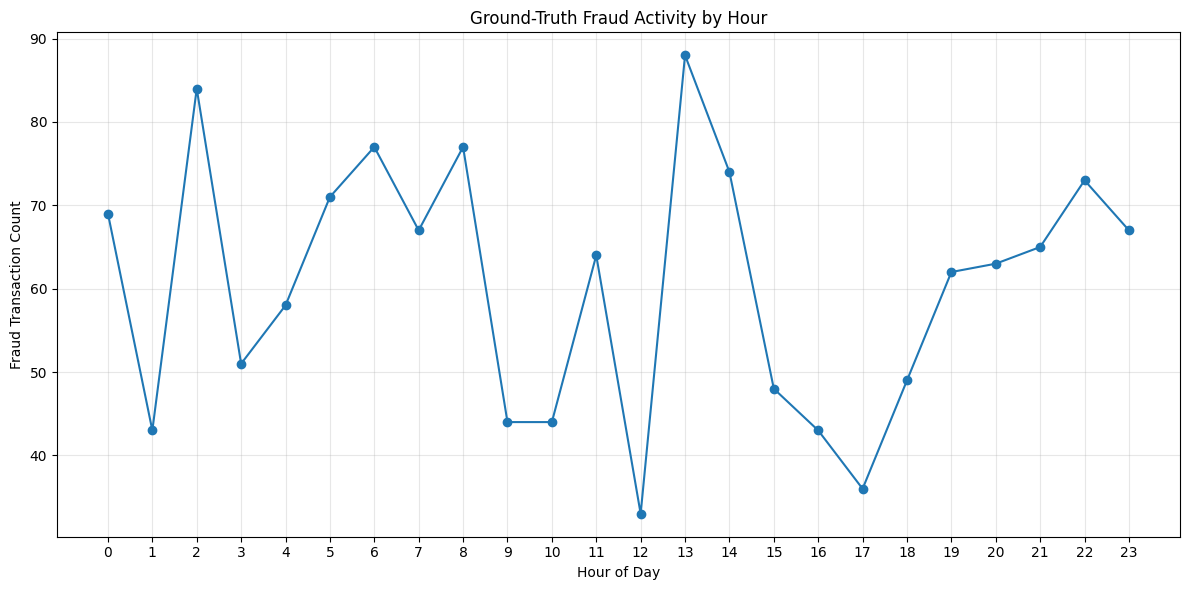

In [ ]:
plt.figure(figsize=(12, 6))

plt.plot(
    hourly_activity["hour"],
    hourly_activity["fraud_count"],
    marker="o"
)

plt.xlabel("Hour of Day")
plt.ylabel("Fraud Transaction Count")
plt.title("Ground-Truth Fraud Activity by Hour")

plt.xticks(range(24))

plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(
        FA04_PATH,
        "hourly_fraud_activity.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
weekday_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

weekday_activity = (
    df.groupby("day_of_week")
      .agg(
          transaction_count=("transaction_id", "count"),
          total_amount=("amount", "sum"),
          fraud_count=("is_fraud", "sum")
      )
      .reindex(weekday_order)
      .reset_index()
)

weekday_activity["fraud_rate_percent"] = (
    weekday_activity["fraud_count"]
    /
    weekday_activity["transaction_count"]
    * 100
)

display(weekday_activity)

,day_of_week,transaction_count,total_amount,fraud_count,fraud_rate_percent
0,Monday,21862,5.310456e+08,396,1.811362
1,Tuesday,21807,5.744521e+08,631,2.893566
2,Wednesday,21072,5.015063e+08,2,0.009491
3,Thursday,21203,5.010910e+08,0,0.000000
4,Friday,21312,4.947803e+08,0,0.000000
5,Saturday,21657,5.211974e+08,178,0.821905
6,Sunday,21081,4.912507e+08,243,1.152697


In [ ]:
correlation_columns = [
    "amount",
    "sequential_risk",
    "spatial_risk",
    "integrated_risk_score",
    "distance_km",
    "time_gap_minutes",
    "rapid_geo_flag",
    "is_fraud"
]

correlation_df = df[
    correlation_columns
].copy()

display(correlation_df.head())

,amount,sequential_risk,spatial_risk,integrated_risk_score,distance_km,time_gap_minutes,rapid_geo_flag,is_fraud
0,8524.0,0.0,0.0,0.0,0.000000,NaN,0,0
1,3595.0,0.0,0.0,0.0,1498.451932,1402.983333,0,0
2,1275.0,0.0,0.0,0.0,1481.998508,278.800000,0,0
3,3866.0,0.0,0.0,0.0,861.471290,231.600000,0,0
4,921.0,0.0,0.0,0.0,492.443185,593.700000,0,0


In [ ]:
correlation_matrix = (
    correlation_df
    .corr(method="pearson")
)

display(correlation_matrix.round(3))

,amount,sequential_risk,spatial_risk,integrated_risk_score,distance_km,time_gap_minutes,rapid_geo_flag,is_fraud
amount,1.000,-0.013,0.002,-0.011,0.001,-0.001,0.002,0.064
sequential_risk,-0.013,1.000,0.016,0.917,0.014,-0.007,0.016,0.163
spatial_risk,0.002,0.016,1.000,0.414,0.143,-0.103,1.000,0.029
integrated_risk_score,-0.011,0.917,0.414,1.000,0.070,-0.047,0.414,0.160
distance_km,0.001,0.014,0.143,0.070,1.000,0.002,0.143,-0.048
time_gap_minutes,-0.001,-0.007,-0.103,-0.047,0.002,1.000,-0.103,0.003
rapid_geo_flag,0.002,0.016,1.000,0.414,0.143,-0.103,1.000,0.029
is_fraud,0.064,0.163,0.029,0.160,-0.048,0.003,0.029,1.000


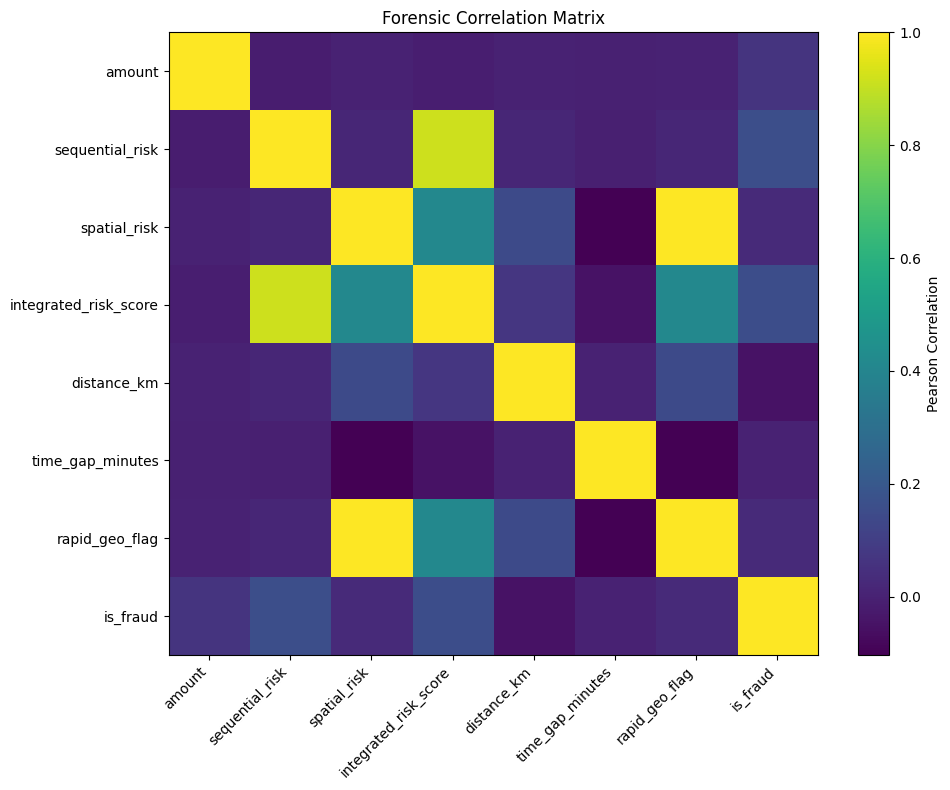

In [ ]:
plt.figure(figsize=(10, 8))

plt.imshow(
    correlation_matrix,
    aspect="auto"
)

plt.colorbar(
    label="Pearson Correlation"
)

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)

plt.title("Forensic Correlation Matrix")

plt.tight_layout()

plt.savefig(
    os.path.join(
        FA04_PATH,
        "forensic_correlation_heatmap.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
corr_pairs = []

columns = correlation_matrix.columns

for i in range(len(columns)):
    for j in range(i + 1, len(columns)):

        corr_pairs.append({
            "variable_1": columns[i],
            "variable_2": columns[j],
            "correlation": correlation_matrix.iloc[i, j],
            "absolute_correlation": abs(
                correlation_matrix.iloc[i, j]
            )
        })

corr_pairs_df = pd.DataFrame(corr_pairs)

corr_pairs_df = corr_pairs_df.sort_values(
    "absolute_correlation",
    ascending=False
)

display(corr_pairs_df.head(15))

,variable_1,variable_2,correlation,absolute_correlation
16,spatial_risk,rapid_geo_flag,1.000000,1.000000
8,sequential_risk,integrated_risk_score,0.916702,0.916702
13,spatial_risk,integrated_risk_score,0.413885,0.413885
20,integrated_risk_score,rapid_geo_flag,0.413885,0.413885
12,sequential_risk,is_fraud,0.162824,0.162824
21,integrated_risk_score,is_fraud,0.159631,0.159631
23,distance_km,rapid_geo_flag,0.142812,0.142812
14,spatial_risk,distance_km,0.142812,0.142812
15,spatial_risk,time_gap_minutes,-0.103237,0.103237
25,time_gap_minutes,rapid_geo_flag,-0.103237,0.103237


In [ ]:

daily_activity.to_csv(
    os.path.join(
        FA04_PATH,
        "daily_transaction_analysis.csv"
    ),
    index=False
)

temporal_spikes.to_csv(
    os.path.join(
        FA04_PATH,
        "temporal_spikes.csv"
    ),
    index=False
)

hourly_activity.to_csv(
    os.path.join(
        FA04_PATH,
        "hourly_transaction_analysis.csv"
    ),
    index=False
)

weekday_activity.to_csv(
    os.path.join(
        FA04_PATH,
        "weekday_transaction_analysis.csv"
    ),
    index=False
)

print("Temporal analysis outputs saved.")

Temporal analysis outputs saved.


In [ ]:
correlation_matrix.to_csv(
    os.path.join(
        FA04_PATH,
        "forensic_correlation_matrix.csv"
    )
)

corr_pairs_df.to_csv(
    os.path.join(
        FA04_PATH,
        "forensic_correlation_pairs.csv"
    ),
    index=False
)

print("Correlation outputs saved.")

Correlation outputs saved.


In [ ]:
strongest_pair = corr_pairs_df.iloc[0]

fa04_summary = pd.DataFrame({
    "metric": [
        "Total transactions",
        "Number of days",
        "Number of spike days",
        "Number of hours analysed",
        "Strongest correlation variable 1",
        "Strongest correlation variable 2",
        "Strongest correlation value"
    ],
    "value": [
        len(df),
        len(daily_activity),
        len(temporal_spikes),
        len(hourly_activity),
        strongest_pair["variable_1"],
        strongest_pair["variable_2"],
        strongest_pair["correlation"]
    ]
})

display(fa04_summary)

fa04_summary.to_csv(
    os.path.join(
        FA04_PATH,
        "FA04_summary.csv"
    ),
    index=False
)

print("FA04 completed successfully.")

,metric,value
0,Total transactions,149994
1,Number of days,7
2,Number of spike days,0
3,Number of hours analysed,24
4,Strongest correlation variable 1,spatial_risk
5,Strongest correlation variable 2,rapid_geo_flag
6,Strongest correlation value,1.0


FA04 completed successfully.


# FA_04 — Temporal & Correlation Analysis

## Financial Crime Analytics & Money Laundering Investigation Platform

### Objective

This notebook investigates financial transactions from two forensic
perspectives:

1. Temporal Analysis
2. Correlation Analysis

Temporal analysis examines transaction activity across dates and hours
to identify unusual activity patterns and transaction-volume changes.

Correlation analysis examines relationships between transaction amounts,
risk indicators, geographic variables and other numerical features.

### Workflow

1. Load transaction-level data
2. Prepare timestamp features
3. Analyze daily transaction activity
4. Analyze hourly transaction activity
5. Analyze fraud activity over time
6. Identify temporal spikes
7. Calculate correlations between important variables
8. Visualize the correlation matrix
9. Save forensic outputs

### Important Note

Temporal spikes and correlations are investigative indicators.

They do not independently establish fraudulent activity.